# Figure 2 — all panels

REDUX read processing across sequencing technologies (panel A) plus tumour molecular profiles
(panels B/C/D: variant burden, SNV 96-context spectrum, SV class composition, cross-platform
concordance), for **Illumina**, **Roche** and **Ultima**.

Panel A uses REDUX alignment outputs; panels B/C/D use PURPLE and sigs somatic outputs. The
published figure uses the five cell lines sequenced on all three platforms, tumour/normal.
Point the Configuration cell at other runs — or your own oncoanalyser output — and run all
cells; see **Data access** below.

## Data access

Every input below is public **oncoanalyser** output, published in two Google Cloud Storage
buckets. Nothing else is needed to reproduce this figure.

| Bucket | Content | Size |
| --- | --- | --- |
| `gs://hartwig-oapaper-celllines` | 5 cell lines x 3 sequencing platforms, WGS and targeted panel | 36 GB |
| `gs://hartwig-oapaper-patients` | 2 consented patients, fresh-frozen and FFPE WGS, targeted panel | — |

### Folder scheme

Every pipeline run has one folder, built from the same fields in the same order —
**sample, modality, platform, aligner, run type, pipeline**:

```text
gs://hartwig-oapaper-celllines/<sample>/<modality>/<platform>/<aligner>/<run type>/<pipeline>/
gs://hartwig-oapaper-patients/<sample>/<modality>/<preservation>/<platform>/<aligner>/<run type>/<pipeline>/

<sample>        COLO829 | HCC1187 | HCC1395 | HCC1954 | HG008      cell lines
                H00005238 | H00006429                              patients
<modality>      wgs | panel                 panel = HMF oncopanel v3, Illumina only
<preservation>  ff | ffpe                   patients only
<platform>      illumina_novaseq6000 | roche_sbx | ultima_ug100
<aligner>       bwa
<run type>      tn = tumour/normal | to = tumour-only
<pipeline>      oa3 = oncoanalyser 3.x
```

So COLO829, Illumina WGS, tumour/normal is:

```text
gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

Inside `oa3/` are the oncoanalyser output directories exactly as the pipeline writes them —
`alignments/`, `bamtools/`, `purple/`, `sage/`, `linx/`, `sigs/`, `logs/`, ... — with **no**
`results/<subject>` level in between.

Sample names inside a run are *not* uniform: tumours are `<sample>T`, but normals are
`<sample>R` for COLO829, HG008 and the patients and `<sample>BL` for HCC1187/HCC1395/HCC1954,
and the Illumina COLO829 WGS run uses `COLO829v012T` / `COLO829v012R` throughout. Nothing
hard-codes them — every notebook reads the real names out of `alignments/` and `purple/`.

Browse it with:

```bash
gsutil ls gs://hartwig-oapaper-celllines/
gsutil ls gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

### What this notebook reads (~235 MB)

Fifteen run folders — 5 cell lines x 3 platforms, WGS, tumour/normal:

```text
gs://hartwig-oapaper-celllines/<cell line>/wgs/<platform>/bwa/tn/oa3/
  logs/<cell line>_<sample>.redux.command.log         panel A   unmapping / duplicate stats
  alignments/<sample>/<sample>.redux.bqr.tsv          panel A   base-quality recalibration
  alignments/<sample>/<sample>.redux.ms_table.tsv.gz  panel A   microsatellite jitter
  bamtools/<sample>/<sample>.bam_metric.summary.tsv   panel A   yield, coverage, uniformity
  purple/<tumour>.purple.somatic.vcf.gz               panels B/C/D   SNV / MNV / indel
  purple/<tumour>.purple.sv.vcf.gz                    panel B/D      SV classes
  purple/<tumour>.purple.cnv.somatic.tsv              panel B        CNA
  purple/<tumour>.purple.purity.tsv                   panel B        ploidy
  sigs/<tumour>.sig.snv_counts.csv                    panel C        SBS96 spectrum
```

`<cell line>` is COLO829, HCC1187, HCC1395, HCC1954 or HG008; `<platform>` is
`illumina_novaseq6000`, `roche_sbx` or `ultima_ug100`. Both tumour and normal are read for
panel A, tumour only for B/C/D. The PURPLE somatic VCFs dominate the download.

### Option 1 — read straight from the bucket (the default; nothing to download first)

Leave the `gs://` values in the Configuration cell as they are and run all cells. Only the
files listed above are staged, into `data/`, and re-used on every later run — delete that
directory to re-fetch. You need the
[Google Cloud SDK](https://cloud.google.com/sdk/docs/install) on `PATH`, authenticated once:

```bash
gcloud auth login      # any Google account works; the buckets are public, this only sets the billing/quota project
```

### Option 2 — copy the data down first, then work offline

Mirror only the run folders this notebook needs (sizes above), then repoint the
Configuration cell at the copy:

```bash
DEST=~/oapaper-data          # anywhere with enough free space
for CL in COLO829 HCC1187 HCC1395 HCC1954 HG008; do
  for P in illumina_novaseq6000 roche_sbx ultima_ug100; do
    gcloud storage rsync -r \
      gs://hartwig-oapaper-celllines/$CL/wgs/$P/bwa/tn/oa3 \
      $DEST/$CL/wgs/$P/bwa/tn/oa3
  done
done          # 10.5 GB for all fifteen complete run folders
```

Then, in the Configuration cell:

```python
CELLLINES_ROOT = "/absolute/path/to/oapaper-data"   # the $DEST above
```

Local paths must be **absolute** — `~` is not expanded, so `~/oapaper-data` fails with
`FileNotFoundError`. `gcloud storage rsync` is resumable: re-run it after an interruption.

### Option 3 — run it on your own oncoanalyser output

Point the Configuration cell at any oncoanalyser 3.x run directory, local or `gs://`. The
only requirement is that the directory contains the tool sub-folders listed above; the
sample names are read from the files themselves, so they do not have to match ours.

Mirroring the complete run folders is 10.5 GB because it brings LINX, ORANGE, CUPPA and the
rest along. If you only want this figure offline, run Option 1 once instead: the `data/redux/`
and `data/purple/` caches it leaves behind are the ~235 MB listed above and are re-used
verbatim on every later run.


## 1 · Configuration

In [ ]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
#
# A run folder is addressed by its fields rather than hard-coded, using the
# scheme described in Data access above:
#
#   <CELLLINES_ROOT>/<cell line>/<MODALITY>/<platform>/<ALIGNER>/<RUN_TYPE>/<PIPELINE>
#
# run_dir() (section 3) assembles that path; every loader goes through it, so
# switching to a local copy is a one-line change to CELLLINES_ROOT.
# ============================================================================
CELLLINES_ROOT = "gs://hartwig-oapaper-celllines"   # or an absolute path to a local copy

PLATFORMS = OrderedDict([                      # label -> bucket folder + plot colour
    ("Illumina", {"dir": "illumina_novaseq6000", "color": "#E08214"}),
    ("Roche",    {"dir": "roche_sbx",            "color": "#2C6FBB"}),
    ("Ultima",   {"dir": "ultima_ug100",         "color": "#3A3A3A"}),
])
CELL_LINES = ["COLO829", "HCC1187", "HCC1395", "HCC1954", "HG008"]
MODALITY   = "wgs"       # wgs | panel
ALIGNER    = "bwa"
RUN_TYPE   = "tn"        # tn = tumour/normal | to = tumour-only
PIPELINE   = "oa3"       # oncoanalyser 3.x
# ============================================================================

# --- Panel A (REDUX) parameters ---
TUMOR_SUFFIXES  = ("T",)
NORMAL_SUFFIXES = ("R", "BL")
READ_TYPE = "NONE"
MIN_READS = 20000
MAX_LEN   = 15
REDUX_BQR   = "redux.bqr.tsv"
REDUX_MS    = "redux.ms_table.tsv.gz"
BAM_SUMMARY = "bam_metric.summary.tsv"

# --- Panels B/C/D (molecular) parameters ---
LOSS_MAX_CN = 0.5      # CNA: deep loss if copyNumber <= this
GAIN_MULT   = 3.0      # CNA: high gain if copyNumber >= GAIN_MULT * ploidy
VAF_MIN     = 0.10     # high-confidence subset: tumour FORMAT AF >= this

REDUX_CACHE  = Path("data") / "redux"
PURPLE_CACHE = Path("data") / "purple"
EXPORT_DIR   = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)

def run_dir(cell_line, platform):
    """The oncoanalyser run folder for one cell line on one platform."""
    return (f"{str(CELLLINES_ROOT).rstrip('/')}/{cell_line}/{MODALITY}"
            f"/{PLATFORMS[platform]['dir']}/{ALIGNER}/{RUN_TYPE}/{PIPELINE}")

print("Cell lines:", CELL_LINES)
for _p in PLATFORMS:
    print(f"  {_p:9s} {run_dir(CELL_LINES[0], _p)}")

## 2 · Plotting style

In [2]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 8, "axes.titlesize": 9, "axes.labelsize": 8, "axes.titleweight": "bold",
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

# COSMIC SBS 6-class palette
SBS_COLORS = {"C>A": "#03BCEE", "C>G": "#000000", "C>T": "#E32926",
              "T>A": "#CACACA", "T>C": "#A1CE63", "T>G": "#EDBFC2"}
SBS_ORDER   = list(SBS_COLORS)
SBS_CLASSES = list(SBS_COLORS)

# Panel A (REDUX)
JIT_INS = "#3B6FB6"; JIT_DEL = "#C0392B"; DOT = "#555555"
UNMAP_COLORS = OrderedDict([("high depth", "#D1495B"), ("soft-clip", "#E08214"), ("chimeric", "#2C6FBB")])
DUP_CORAL = "#E4572E"
FACETS = OrderedDict([
    ("A/T",   ["A/T"]),
    ("C/G",   ["C/G"]),
    ("2 bp",  ["AT/TA", "AC/CA/GT/TG", "AG/GA/CT/TC", "CG/GC"]),
    ("≥3 bp", ["3bp repeat", "4bp repeat", "5bp repeat"]),
])

# Panels B/C/D (molecular)
SV_ORDER  = ["DEL", "DUP", "INS", "INV", "BND", "SGL"]
SV_COLORS = {"DEL": "#4C72B0", "DUP": "#DD8452", "INS": "#55A868",
             "INV": "#C44E52", "BND": "#8172B3", "SGL": "#937860"}
VAR_TYPES = ["SNV", "MNV", "indel", "SV", "CNA"]

def human(n):
    n = float(n)
    for unit, div in (("B", 1e9), ("M", 1e6), ("k", 1e3)):
        if abs(n) >= div:
            return f"{n/div:.2f}{unit}"
    return f"{n:.0f}"

def fmt(n):
    n = float(n)
    return f"{n/1000:.1f}k" if n >= 1000 else f"{n:.0f}"

## 3 · Panel A — load REDUX outputs, run-log stats and yield metrics

In [ ]:
import subprocess, re
import numpy as np
import pandas as pd

def _ls(path):
    if str(path).startswith("gs://"):
        r = subprocess.run(["gsutil", "ls", str(path)], capture_output=True, text=True)
        return [l for l in r.stdout.splitlines() if l.strip()]
    p = Path(path)
    return [str(c) + ("/" if c.is_dir() else "") for c in p.iterdir()] if p.exists() else []

def _cat(src):
    if str(src).startswith("gs://"):
        return subprocess.run(["gsutil", "cat", str(src)], check=True,
                              capture_output=True, text=True).stdout
    return Path(src).read_text()

def _fetch(src, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        return dest
    if str(src).startswith("gs://"):
        subprocess.run(["gsutil", "cp", str(src), str(dest)], check=True,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    else:
        import shutil; shutil.copy(Path(src), dest)
    return dest

def _classify(sample):
    # Tumour vs normal from the sample-name suffix (BL checked before R: "...BL" also ends in 'L').
    for suf in NORMAL_SUFFIXES:
        if sample.endswith(suf):
            return "N"
    for suf in TUMOR_SUFFIXES:
        if sample.endswith(suf):
            return "T"
    return None

def discover_tn(platform):
    # Return [(cell_line, {"T": sample|None, "N": sample|None}, base), ...] for one platform.
    # Sample names are read from <run>/alignments/, so they need not follow our convention.
    found = []
    for cl in CELL_LINES:
        base = run_dir(cl, platform)
        subdirs = [e.rstrip("/").split("/")[-1] for e in _ls(base + "/alignments/") if e.endswith("/")]
        if not subdirs:
            print(f"WARN: no alignments/ under {base} -- skipping {cl}/{platform}")
            continue
        samples = {"T": None, "N": None}
        for s in subdirs:
            tis = _classify(s)
            if tis and samples[tis] is None:
                samples[tis] = s
        if samples["T"] or samples["N"]:
            found.append((cl, samples, base))
    return found

_COMP = {"A": "T", "T": "A", "C": "G", "G": "C"}
def bqr_delta(bqr_df, read_type=READ_TYPE):
    # {(sbs, OriginalQual): mean(recalibrated - original)} at the highest (top) quality bin only.
    b = bqr_df[(bqr_df["ReadType"] == read_type) & (bqr_df["Alt"] != bqr_df["Ref"])].copy()
    top_bin = b["OriginalQual"].max()
    b = b[b["OriginalQual"] == top_bin]
    b["sbs"] = [r + ">" + a if r in "CT" else _COMP[r] + ">" + _COMP[a]
                for r, a in zip(b["Ref"], b["Alt"])]
    out = {}
    for (s, q), g in b.groupby(["sbs", "OriginalQual"]):
        out[(s, int(q))] = float(np.average(g["RecalibratedQual"], weights=g["Count"])) - int(q)
    quals = sorted(b["OriginalQual"].unique())
    return out, quals

def _dev_cols(df):
    cols = [c for c in df.columns if c.startswith("count")]
    devs = np.array([int(c.replace("count", "").replace("+", "")) for c in cols])
    o = np.argsort(devs)
    return [cols[i] for i in o], devs[o]

def jitter_insdel(ms_df, consensus=READ_TYPE):
    # {facet: DataFrame[length, phred_ins, phred_del]} per cell line.
    cols, devs = _dev_cols(ms_df)
    out = {}
    for name, units in FACETS.items():
        sub = ms_df[(ms_df["unit"].isin(units)) & (ms_df["consensusType"] == consensus)]
        rows = []
        for L, grp in sub.groupby("numUnits"):
            if L > MAX_LEN:
                continue
            c = grp[cols].to_numpy().sum(axis=0).astype(float); tot = c.sum()
            if tot < MIN_READS:
                continue
            ins = c[devs > 0].sum() / tot; dele = c[devs < 0].sum() / tot
            rows.append((int(L),
                         (-10*np.log10(ins) if ins > 0 else np.nan),
                         (-10*np.log10(dele) if dele > 0 else np.nan)))
        out[name] = pd.DataFrame(rows, columns=["length", "phred_ins", "phred_del"]).sort_values("length")
    return out

# ---- REDUX run-log parsing (tolerant of platform-specific formats) ---------------------------
_REASON_LABEL = {"depth": "high depth", "softClip": "soft-clip", "chimeric": "chimeric"}
def parse_log_stats(text):
    s = {}
    m = re.search(r"reasons\(([^)]*)\)", text)            # e.g. reasons(depth=.. softClip=.. chimeric=..)
    if m:
        reasons = {}
        for kv in m.group(1).split():
            k, _, v = kv.partition("=")
            if v.isdigit():
                reasons[_REASON_LABEL.get(k, k)] = int(v)
        s["unmap_reasons"] = reasons
    m = re.search(r"loaded (\d+) unmapping regions", text)
    if m:
        s["unmap_regions"] = int(m.group(1))
    m = re.search(r"totalReads\((\d+)\) duplicates\((\d+)\) dupGroups\((\d+)\) umiGroups\((\d+)\)", text)
    if m:
        s.update(total_reads=int(m.group(1)), duplicates=int(m.group(2)),
                 dup_groups=int(m.group(3)), umi_groups=int(m.group(4)))
    if re.search(r"duplicate marking:\s*disabled", text):
        s["dedup_disabled"] = True
    return s

def fetch_log_stats(cl, sample, base, dest):
    # Cache only the handful of relevant log lines, then parse them.
    cache = dest / f"{sample}.logstats.txt"
    if not cache.exists():
        src = f"{base}/logs/{cl}_{sample}.redux.command.log"
        try:
            txt = _cat(src)
        except Exception as e:
            print(f"WARN: no REDUX log for {cl}/{sample}: {e}")
            return {}
        keep = [l for l in txt.splitlines()
                if ("unmapped stats:" in l or "stats: totalReads" in l
                    or "unmapping regions from" in l or "duplicate marking:" in l)]
        cache.parent.mkdir(parents=True, exist_ok=True)
        cache.write_text("\n".join(keep))
    return parse_log_stats(cache.read_text())

# ---- bamtools yield / coverage summary -------------------------------------------------------
_SUMMARY_MAP = OrderedDict([
    ("TotalReads", "total_reads"), ("MeanCoverage", "mean_cov"),
    ("StdDevCoverage", "std_cov"), ("MedianCoverage", "median_cov"),
    ("MadCoverage", "mad_cov"),   ("TotalRegionBases", "total_region_bases"),
    ("DuplicatePercent", "dup_pct"), ("UnmappedPercent", "unmapped_pct"),
])
def fetch_summary_stats(cl, sample, base, dest):
    # One-row bamtools summary -> yield/coverage dict, with derived total-bases (Gb) and uniformity.
    cache = dest / f"{sample}.summary.tsv"
    src = f"{base}/bamtools/{sample}/{sample}.{BAM_SUMMARY}"
    try:
        path = _fetch(src, cache)
    except Exception as e:
        print(f"WARN: no bamtools summary for {cl}/{sample}: {e}")
        return {}
    df = pd.read_csv(path, sep="\t")
    row = df.iloc[0]
    out = {key: float(row[col]) for col, key in _SUMMARY_MAP.items() if col in df.columns}
    if out.get("total_region_bases") and out.get("mean_cov"):
        out["total_bases_gb"] = out["mean_cov"] * out["total_region_bases"] / 1e9   # aligned bases in metrics regions
    med = out.get("median_cov")
    out["uniformity"] = (out["mad_cov"] / med) if (med and out.get("mad_cov") is not None) else np.nan  # MAD/Median
    return out

def _load_sample(name, cl, sample, base):
    dest = REDUX_CACHE / name / cl
    bqr = pd.read_csv(_fetch(f"{base}/alignments/{sample}/{sample}.{REDUX_BQR}",
                             dest / f"{sample}.bqr.tsv"), sep="\t")
    ms = pd.read_csv(_fetch(f"{base}/alignments/{sample}/{sample}.{REDUX_MS}",
                            dest / f"{sample}.ms_table.tsv.gz"), sep="\t", compression="gzip")
    delta, quals = bqr_delta(bqr)
    return {"sample": sample, "bqr_delta": delta, "quals": quals,
            "jitter": jitter_insdel(ms),
            "log": fetch_log_stats(cl, sample, base, dest),
            "summary": fetch_summary_stats(cl, sample, base, dest)}

def load_redux_platform(name):
    disc = {cl: (samples, base) for cl, samples, base in discover_tn(name)}
    order = [cl for cl in CELL_LINES if cl in disc]
    groups = []
    for cl in order:
        samples, base = disc[cl]
        g = {"cell_line": cl, "T": None, "N": None}
        for tis in ("T", "N"):
            if samples[tis]:
                g[tis] = _load_sample(name, cl, samples[tis], base)
        groups.append(g)
    return groups

def _unmap_frac(rec):
    tot = rec["summary"].get("total_reads")
    return (sum(rec["log"].get("unmap_reasons", {}).values()) / tot) if tot else float("nan")

REDUX_DATA = {name: load_redux_platform(name) for name in PLATFORMS}
for name, groups in REDUX_DATA.items():
    print(f"{name}: {len(groups)} cell lines")
    for g in groups:
        for tis in ("T", "N"):
            r = g[tis]
            if not r:
                continue
            sm, lg = r["summary"], r["log"]
            dup = "disabled" if lg.get("dedup_disabled") else (
                  f"{sm['dup_pct']:.1%}" if sm.get("dup_pct") is not None else "n/a")
            print(f"    {g['cell_line']:8s} {tis} [{r['sample']:>14s}]  "
                  f"reads={human(sm.get('total_reads', 0)):>7s}  "
                  f"bases={sm.get('total_bases_gb', float('nan')):5.0f}Gb  "
                  f"meancov={sm.get('mean_cov', float('nan')):4.0f}  "
                  f"unif={sm.get('uniformity', float('nan')):.2f}  "
                  f"unmap={_unmap_frac(r):.2%}  dup={dup}  "
                  f"groups={human(lg['dup_groups']) if lg.get('dup_groups') else '-'}")

## 4 · Panel A — drawing helpers

In [4]:
from matplotlib.lines import Line2D

# tumour above / normal below within each cell-line group; normal is white-hatched or open.
TN_OFFSET = 0.19          # vertical offset of T / N sub-bars from the cell-line centre
TN_H      = 0.34          # sub-bar height
HATCH     = "////"        # normal fill hatch (drawn white via edgecolor)
TN_ROWS   = (("T", TN_OFFSET, None), ("N", -TN_OFFSET, HATCH))

# Legend handles reused as figure-level legends placed under each column-group title.
UNMAP_HANDLES  = [Patch(facecolor=UNMAP_COLORS[k], label=k) for k in UNMAP_COLORS]
JITTER_HANDLES = [
    Line2D([0], [0], marker="o", color="none", markerfacecolor=JIT_INS, markeredgecolor="white", label="insertion"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor=JIT_DEL, markeredgecolor="white", label="deletion"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="#777", markeredgecolor="white", label="tumour"),
    Line2D([0], [0], marker="o", color="none", markerfacecolor="white", markeredgecolor="#777", markeredgewidth=0.9, label="normal"),
]

def _grp_y(ax, groups):
    n = len(groups)
    y = np.arange(n)[::-1]                 # first cell line on top
    ax.set_ylim(-0.7, n - 0.3)
    ax.set_yticks(y)
    return y

def _recs(groups, tis):
    return [g[tis] for g in groups if g[tis]]

def _yield_vals(rec):
    # Pre-REDUX (raw) vs post-REDUX yield. Unmapping re-flags reads rather than deleting them,
    # so post = raw x (1 - f), f = unmapped fraction; raw is grossed up as post / (1 - f).
    sm, lg = rec["summary"], rec["log"]
    T    = sm.get("total_reads")
    cov  = sm.get("mean_cov")
    base = sm.get("total_bases_gb")
    U    = sum(lg.get("unmap_reasons", {}).values()) if lg.get("unmap_reasons") else 0
    f    = (U / T) if (T and U) else 0.0
    keep = 1.0 - f
    pre  = {"reads": T,
            "cov":   (cov  / keep) if (cov  and keep) else cov,
            "bases": (base / keep) if (base and keep) else base}
    post = {"reads": (T * keep) if T else None, "cov": cov, "bases": base,
            "unif": sm.get("uniformity")}
    return pre, post

def draw_yield_panel(ax, groups, *, phase, show_header=False):
    # Text grid of sequencing yield per cell line (tumour above, normal below).
    #   phase="pre"  -> raw reads / mean coverage / bases before unmapping (derived; see _yield_vals)
    #   phase="post" -> measured post-REDUX reads / mean coverage / bases + coverage uniformity
    y = _grp_y(ax, groups)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xticks([]); ax.tick_params(axis="y", length=0)
    ax.set_yticklabels([g["cell_line"] for g in groups], fontsize=6.5, weight="bold")
    if phase == "pre":
        cols  = [(0.44, "reads"), (0.74, "cov"), (0.99, "bases")]
        heads = [(0.44, "reads", "right"), (0.74, "mean\ncov.", "right"),
                 (0.99, "bases\n(Gb)", "right")]
    else:
        cols  = [(0.30, "reads"), (0.52, "cov"), (0.72, "bases"), (0.99, "unif")]
        heads = [(0.30, "reads", "right"), (0.52, "mean\ncov.", "right"),
                 (0.72, "bases\n(Gb)", "right"), (0.99, "uniformity\n(MAD/median)", "right")]
    tr = ax.get_yaxis_transform()          # x = axes fraction, y = data
    for yi, g in zip(y, groups):
        for tis, off, _h in TN_ROWS:
            r = g[tis]; yy = yi + off
            col = "#333" if tis == "T" else "#8a8a8a"
            ax.text(0.0, yy, tis, va="center", ha="left", fontsize=5.6, color=col,
                    weight="bold", transform=tr)
            if not r:
                continue
            pre, post = _yield_vals(r)
            m = pre if phase == "pre" else post
            unif = m.get("unif")
            vals = {
                "reads": human(m["reads"]) if m.get("reads") else "—",
                "cov":   f"{m['cov']:.0f}"   if m.get("cov")   else "—",
                "bases": f"{m['bases']:.0f}" if m.get("bases") else "—",
                "unif":  f"{unif:.2f}" if (unif is not None and unif == unif) else "—",
            }
            for x, key in cols:
                ax.text(x, yy, vals[key], va="center", ha="right", fontsize=5.6,
                        color=col, transform=tr)
    if show_header:
        for x, lab, ha in heads:
            ax.text(x, 1.02, lab, va="bottom", ha=ha, fontsize=5.4, weight="bold",
                    color="#333", transform=ax.transAxes, linespacing=0.95)

def draw_unmap_row(ax, groups, *, xmax, show_xlabel=False):
    # Paired bars: length = unmapped reads / total reads; segments = reason composition; % annotated.
    # (Reason legend is drawn at figure level, under the column-group title.)
    reasons_order = list(UNMAP_COLORS)
    y = _grp_y(ax, groups)
    tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, hatch in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            reasons = r["log"].get("unmap_reasons", {})
            tot = r["summary"].get("total_reads")
            if not tot or not reasons:
                ax.text(0.01, yy, "n/a", va="center", ha="left", fontsize=5, color="#999", transform=tr)
                continue
            left = 0.0
            for reason in reasons_order:
                frac = reasons.get(reason, 0) / tot
                if frac > 0:
                    ax.barh(yy, frac, left=left, height=TN_H, color=UNMAP_COLORS[reason],
                            edgecolor="white", linewidth=0.3, hatch=hatch, zorder=2)
                    left += frac
            ax.text(left + xmax * 0.012, yy, f"{left:.2%}", va="center", ha="left",
                    fontsize=5.0, color="#555")
    ax.set_xlim(0, xmax)
    ax.tick_params(labelleft=False)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    ax.tick_params(labelsize=6)
    if show_xlabel:
        ax.set_xlabel("% of reads unmapped")

def draw_dedup_row(ax, groups, *, xmax, show_xlabel=False):
    # Paired duplicate-% bars per cell line (shared x-axis). Ultima marks no duplicates -> note.
    y = _grp_y(ax, groups)
    tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, hatch in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            lg, sm = r["log"], r["summary"]
            if lg.get("dedup_disabled"):
                ax.text(0.02, yy, "disabled", va="center", ha="left", fontsize=5, color="#999",
                        style="italic", transform=tr)
                continue
            dp = sm.get("dup_pct")
            if dp is None:
                ax.text(0.02, yy, "n/a", va="center", ha="left", fontsize=5, color="#999", transform=tr)
                continue
            ax.barh(yy, dp, height=TN_H, color=DUP_CORAL, edgecolor="white", linewidth=0.3,
                    hatch=hatch, zorder=2)
    ax.set_xlim(0, xmax)
    ax.tick_params(labelleft=False)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
    ax.tick_params(labelsize=6)
    if show_xlabel:
        ax.set_xlabel("duplicate %")

def draw_consensus_col(ax, groups, *, show_title=False):
    # Standalone text column of the consensus (duplicate) group count per sample.
    y = _grp_y(ax, groups)
    ax.set_xlim(0, 1); ax.axis("off")
    tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, _h in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            lg = r["log"]
            if lg.get("dedup_disabled"):
                txt, col = "—", "#999"
            elif lg.get("dup_groups"):
                txt, col = human(lg["dup_groups"]), ("#444" if tis == "T" else "#8a8a8a")
            else:
                txt, col = "n/a", "#999"
            ax.text(0.5, yy, txt, va="center", ha="center", fontsize=5.6, weight="bold",
                    color=col, transform=tr)
    if show_title:
        ax.text(0.5, 1.0, "consensus\ngroups", ha="center", va="bottom", fontsize=6.4, weight="bold",
                transform=ax.transAxes, linespacing=1.05)

def draw_bqr_row(ax, groups, *, show_xlabel=False):
    # Two bars per substitution class: tumour mean (solid) and normal mean (white-hatched).
    x = np.arange(len(SBS_ORDER)); w = 0.36
    recsT, recsN = _recs(groups, "T"), _recs(groups, "N")
    for i, sbs in enumerate(SBS_ORDER):
        for recs, off, hatch in ((recsT, -w/2, None), (recsN, +w/2, HATCH)):
            deltas = [s["bqr_delta"].get((sbs, max(s["quals"])), np.nan) for s in recs]
            if not deltas:
                continue
            ax.bar(i + off, float(np.nanmean(deltas)), width=w, color=SBS_COLORS[sbs],
                   edgecolor="white", linewidth=0.3, hatch=hatch, zorder=2)
            for d in deltas:
                ax.plot(i + off, d, "o", ms=1.7, color=DOT, alpha=0.45, mec="none", zorder=3)
    ax.axhline(0, color="black", lw=0.8, zorder=1)
    ax.set_xlim(-0.6, len(SBS_ORDER) - 0.4)
    ax.set_xticks(x); ax.set_xticklabels(SBS_ORDER, fontsize=6)
    ax.set_ylabel("ΔQ (phred)")
    if show_xlabel:
        ax.set_xlabel("Substitution class")

def draw_absq_panel(ax, groups, *, show_title=False):
    # Achieved absolute recalibrated Q per class: tumour and normal columns.
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    recsT, recsN = _recs(groups, "T"), _recs(groups, "N")
    allq = [max(s["quals"]) for s in recsT + recsN]
    nlab = f"Q{int(min(allq))}" if min(allq) == max(allq) else f"Q{int(min(allq))}–{int(max(allq))}"
    def _absq(recs, sbs):
        vals = [max(s["quals"]) + s["bqr_delta"].get((sbs, max(s["quals"])), np.nan) for s in recs]
        return np.nanmean(vals) if vals else np.nan
    for sbs, yy in zip(SBS_ORDER, np.linspace(0.84, 0.20, len(SBS_ORDER))):
        ax.plot(0.10, yy, "s", ms=6.0, color=SBS_COLORS[sbs], mec="#999", mew=0.3)
        ax.text(0.22, yy, sbs, va="center", ha="left", fontsize=6.0)
        ax.text(0.72, yy, f"{_absq(recsT, sbs):.0f}", va="center", ha="right", fontsize=7.5, weight="bold")
        ax.text(0.99, yy, f"{_absq(recsN, sbs):.0f}", va="center", ha="right", fontsize=7.5,
                weight="bold", color="#8a8a8a")
    ax.text(0.5, 0.04, f"top bin {nlab}", ha="center", fontsize=5.2, color="#777")
    if show_title:
        ax.text(0.5, 1.10, "achieved Q", ha="center", va="bottom", fontsize=7.0, weight="bold")
        ax.text(0.72, 1.0, "T", ha="right", va="bottom", fontsize=6.4, weight="bold")
        ax.text(0.99, 1.0, "N", ha="right", va="bottom", fontsize=6.4, weight="bold", color="#8a8a8a")

def draw_jitter_row(axes, groups, *, show_titles=False):
    # (insertion/deletion & tumour/normal legend is drawn at figure level, under the group title.)
    recsT, recsN = _recs(groups, "T"), _recs(groups, "N")
    for fi, name in enumerate(FACETS):
        a = axes[fi]
        for recs in (recsT, recsN):                     # faint per-sample points
            for s in recs:
                d = s["jitter"][name]
                a.plot(d["length"], d["phred_del"], "o", ms=1.4, color=JIT_DEL, alpha=0.16, mec="none")
                a.plot(d["length"], d["phred_ins"], "o", ms=1.4, color=JIT_INS, alpha=0.16, mec="none")
        for recs, fill in ((recsT, True), (recsN, False)):   # means: tumour filled, normal open
            if not recs:
                continue
            alld = pd.concat([s["jitter"][name] for s in recs])
            if alld.empty:
                continue
            m = alld.groupby("length").mean(numeric_only=True).reset_index()
            for col, c in (("phred_del", JIT_DEL), ("phred_ins", JIT_INS)):
                if fill:
                    a.plot(m["length"], m[col], "o", ms=2.8, color=c, mec="white", mew=0.3)
                else:
                    a.plot(m["length"], m[col], "o", ms=2.8, mfc="white", mec=c, mew=0.9)
        if show_titles:
            a.text(0.5, 1.04, name, transform=a.transAxes, ha="center", va="bottom",
                   fontsize=6.4, weight="bold", color="#444")
        a.set_xlim(3, 16); a.set_xticks([4, 8, 12])
        a.grid(True, lw=0.3, alpha=0.3); a.tick_params(labelsize=6)
        if fi > 0:
            a.tick_params(labelleft=False)
    axes[0].set_ylabel("Phred score")

print("drawing helpers ready")

drawing helpers ready


## 5 · Panel A — composite (REDUX across technologies)

Wrote: figures/redux_comparison_full.pdf figures/redux_comparison_full.svg figures/redux_comparison_full.png


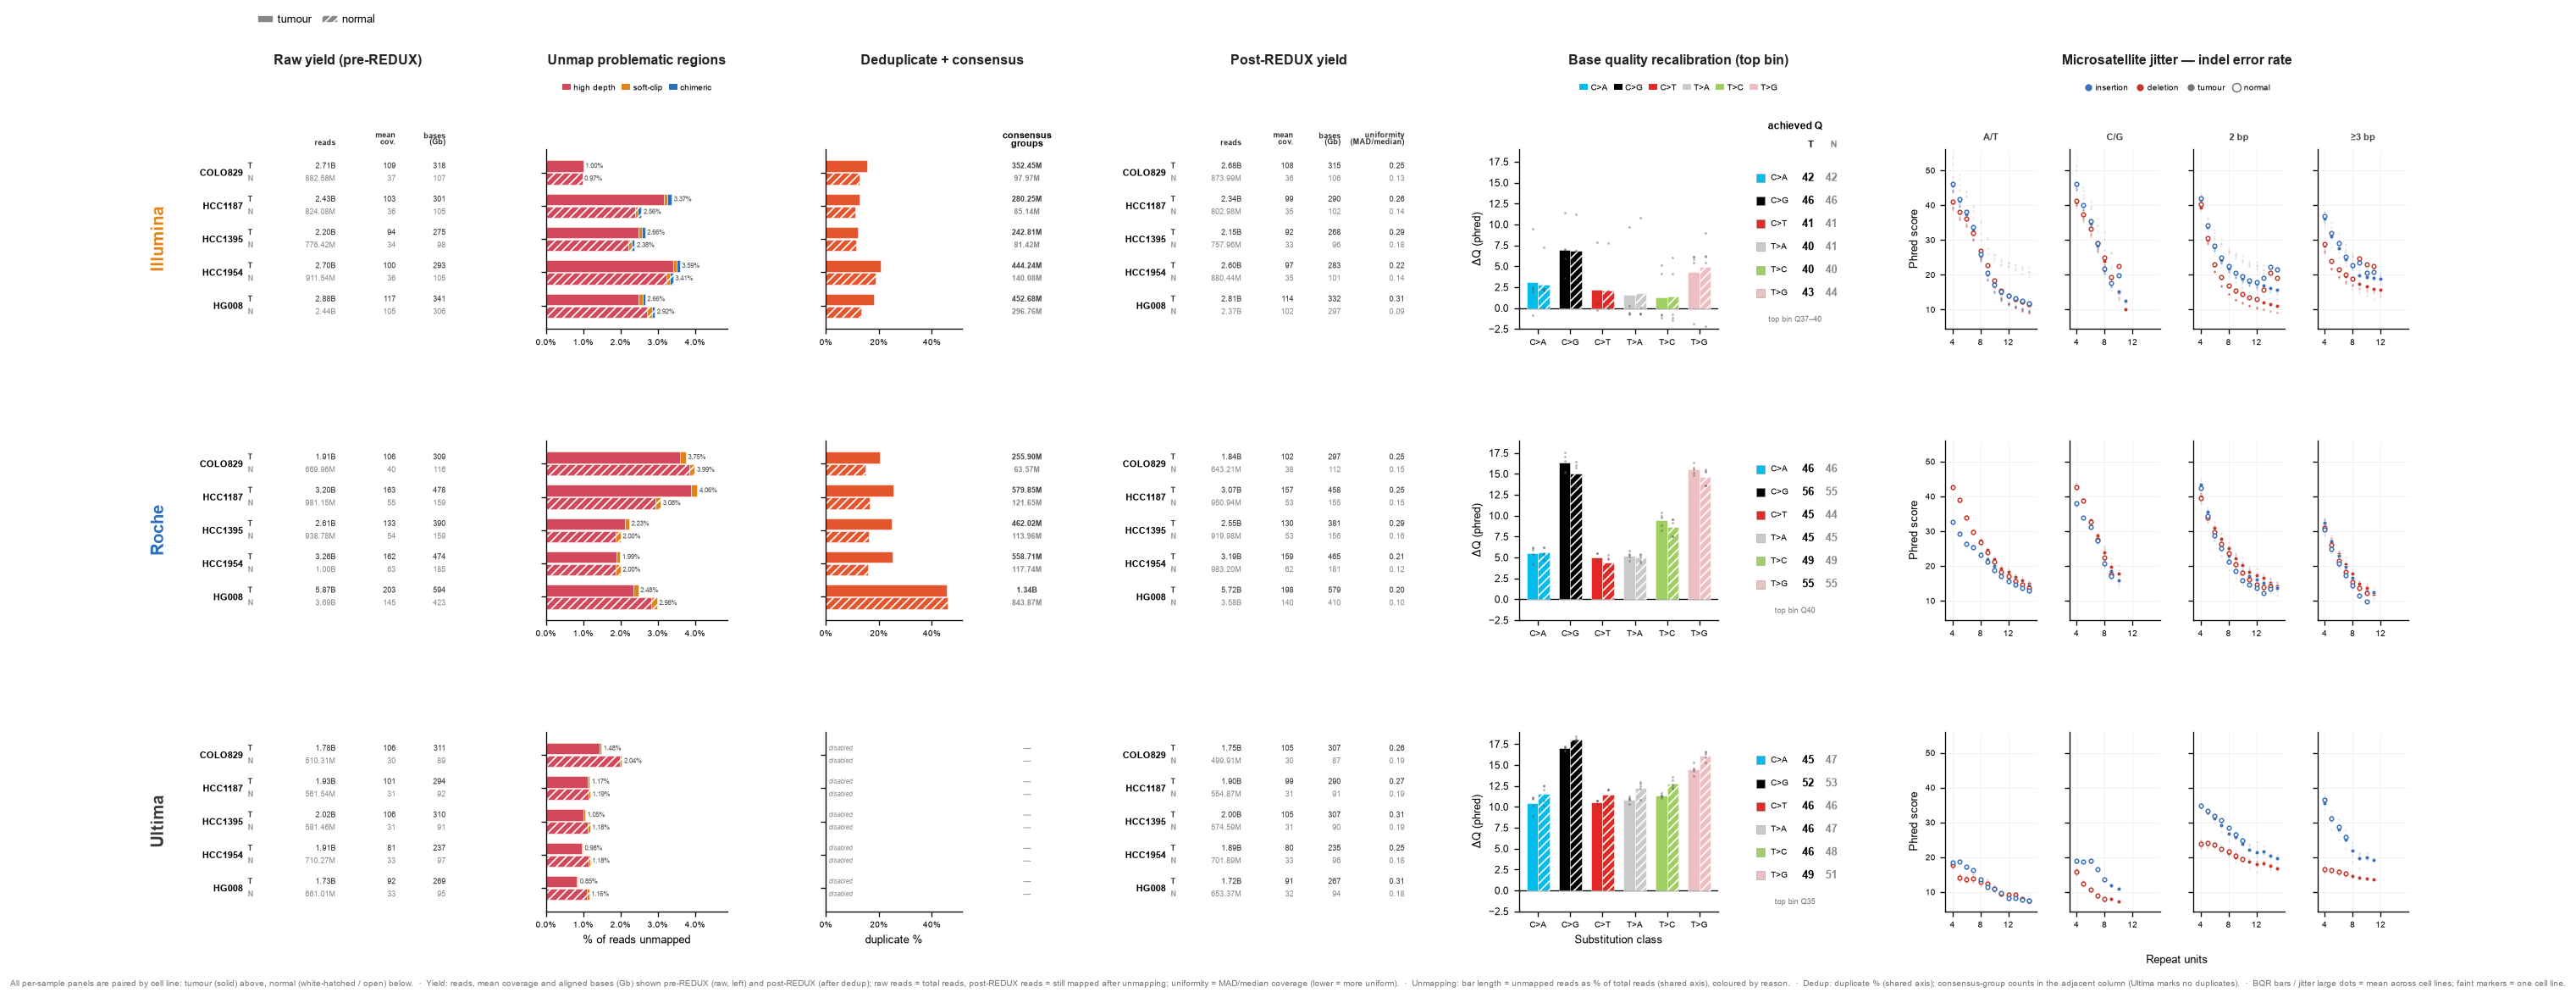

In [5]:
fig = plt.figure(figsize=(22.5, 9.8))
outer = fig.add_gridspec(len(PLATFORMS), 1, hspace=0.62,
                         left=0.045, right=0.99, top=0.85, bottom=0.085)
bqr_ref = jit_ref = None
plats = list(PLATFORMS)
row_axes = []
top_axes = {}

# shared x-limits across all platform rows -----------------------------------------------------
unmap_xmax = max((_unmap_frac(g[t]) for plat in PLATFORMS for g in REDUX_DATA[plat]
                  for t in ("T", "N") if g[t] and _unmap_frac(g[t]) == _unmap_frac(g[t])),
                 default=0.02) * 1.20
dup_xmax = max((g[t]["summary"].get("dup_pct", 0) or 0
                for plat in PLATFORMS for g in REDUX_DATA[plat] for t in ("T", "N")
                if g[t] and not g[t]["log"].get("dedup_disabled")),
               default=0.5) * 1.12

# columns: raw_yield | · | unmap | · | dedup | groups | · | post_yield | · | bqr | absq | · | jitter×4
COL_W = [2.2, 0.35, 2.0, 0.35, 1.5, 0.7, 0.5, 2.6, 0.5, 2.2, 0.95, 0.45, 1.0, 1.0, 1.0, 1.0]

for r, plat in enumerate(plats):
    rg = outer[r].subgridspec(1, len(COL_W), width_ratios=COL_W, wspace=0.32)
    ax_pre    = fig.add_subplot(rg[0])
    ax_unmap  = fig.add_subplot(rg[2])
    ax_dedup  = fig.add_subplot(rg[4])
    ax_groups = fig.add_subplot(rg[5])
    ax_post   = fig.add_subplot(rg[7])
    ax_bqr    = fig.add_subplot(rg[9], sharey=bqr_ref); bqr_ref = bqr_ref or ax_bqr
    ax_absq   = fig.add_subplot(rg[10])
    jax = []
    for i in range(4):
        aj = fig.add_subplot(rg[12 + i], sharey=jit_ref); jit_ref = jit_ref or aj
        jax.append(aj)

    groups = REDUX_DATA[plat]
    is_top = (r == 0); is_bot = (r == len(plats) - 1)
    draw_yield_panel(ax_pre, groups, phase="pre", show_header=is_top)
    draw_unmap_row(ax_unmap, groups, xmax=unmap_xmax, show_xlabel=is_bot)
    draw_dedup_row(ax_dedup, groups, xmax=dup_xmax, show_xlabel=is_bot)
    draw_consensus_col(ax_groups, groups, show_title=is_top)
    draw_yield_panel(ax_post, groups, phase="post", show_header=is_top)
    draw_bqr_row(ax_bqr, groups, show_xlabel=is_bot)
    draw_absq_panel(ax_absq, groups, show_title=is_top)
    draw_jitter_row(jax, groups, show_titles=is_top)

    row_axes.append((plat, ax_pre))
    if is_top:
        top_axes = {"pre": ax_pre, "unmap": ax_unmap, "dedup": ax_dedup, "groups": ax_groups,
                    "post": ax_post, "bqr": ax_bqr, "absq": ax_absq, "jax": jax}

bqr_ref.set_ylim(-2.5, 19)
fig.canvas.draw()

# --- vertical platform row labels (left edge, platform colour) --------------------------------
for plat, ax_left in row_axes:
    p = ax_left.get_position()
    fig.text(0.006, (p.y0 + p.y1) / 2, plat, rotation=90, va="center", ha="center",
             color=PLATFORMS[plat]["color"], weight="bold", fontsize=12)

# --- column-group headers over the top row ----------------------------------------------------
ppre = top_axes["pre"].get_position(); pu = top_axes["unmap"].get_position()
pd_ = top_axes["dedup"].get_position(); pg = top_axes["groups"].get_position()
ppost = top_axes["post"].get_position()
pb = top_axes["bqr"].get_position();   pa = top_axes["absq"].get_position()
pj0 = top_axes["jax"][0].get_position(); pj3 = top_axes["jax"][-1].get_position()
yhead = max(ppre.y1, pu.y1, pb.y1, pj3.y1) + 0.085
def _hdr(x, txt, ha="center"):
    fig.text(x, yhead, txt, fontsize=9.3, weight="bold", ha=ha, color="#222")
_hdr((ppre.x0 + ppre.x1) / 2, "Raw yield (pre-REDUX)")
_hdr((pu.x0 + pu.x1) / 2, "Unmap problematic regions")
_hdr((pd_.x0 + pg.x1) / 2, "Deduplicate + consensus")
_hdr((ppost.x0 + ppost.x1) / 2, "Post-REDUX yield")
_hdr((pb.x0 + pa.x1) / 2, "Base quality recalibration (top bin)")
_hdr((pj0.x0 + pj3.x1) / 2, "Microsatellite jitter — indel error rate")

# tumour/normal encoding legend (shared across all panels), top-left
fig.legend(handles=[Patch(facecolor="#888", edgecolor="white", label="tumour"),
                    Patch(facecolor="#888", edgecolor="white", hatch="////", label="normal")],
           ncol=2, loc="upper left", bbox_to_anchor=(0.045, 0.995), fontsize=7.5,
           frameon=False, handlelength=1.5, columnspacing=1.0, handletextpad=0.4)

# per-column-group legends, each sitting just under its own title -------------------------------
ylegend = yhead - 0.012
fig.legend(handles=UNMAP_HANDLES, ncol=3, loc="upper center",
           bbox_to_anchor=((pu.x0 + pu.x1) / 2, ylegend), fontsize=6, handlelength=1.0,
           columnspacing=0.7, handletextpad=0.35, frameon=False)          # unmapping reasons
fig.legend(handles=[Patch(facecolor=SBS_COLORS[s], label=s) for s in SBS_ORDER],
           ncol=6, loc="upper center", bbox_to_anchor=((pb.x0 + pa.x1) / 2, ylegend),
           fontsize=6, handlelength=1.0, columnspacing=0.7, handletextpad=0.35, frameon=False)  # BQR classes
fig.legend(handles=JITTER_HANDLES, ncol=4, loc="upper center",
           bbox_to_anchor=((pj0.x0 + pj3.x1) / 2, ylegend), fontsize=6, handlelength=1.0,
           columnspacing=0.9, handletextpad=0.35, frameon=False)          # jitter ins/del + T/N

# shared x label for jitter (bottom row)
pjb0 = fig.axes[-4].get_position(); pjb3 = fig.axes[-1].get_position()
fig.text((pjb0.x0 + pjb3.x1) / 2, pjb0.y0 - 0.052, "Repeat units", ha="center", fontsize=8)

# footnote
fig.text(0.5, 0.010,
         "All per-sample panels are paired by cell line: tumour (solid) above, normal (white-hatched / open) below.  ·  "
         "Yield: reads, mean coverage and aligned bases (Gb) shown pre-REDUX (raw, left) and post-REDUX (after dedup); raw reads = total reads, post-REDUX reads = still mapped after unmapping; uniformity = MAD/median coverage (lower = more uniform).  ·  "
         "Unmapping: bar length = unmapped reads as % of total reads (shared axis), coloured by reason.  ·  "
         "Dedup: duplicate % (shared axis); consensus-group counts in the adjacent column (Ultima marks no duplicates).  ·  "
         "BQR bars / jitter large dots = mean across cell lines; faint markers = one cell line.",
         ha="center", fontsize=6.0, color="#777")

stem = EXPORT_DIR / "redux_comparison_full"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()

## 6 · Panels B/C/D — load PURPLE outputs

In [ ]:
import subprocess, re, gzip
from collections import Counter
import numpy as np
import pandas as pd

def _ls(path):
    if str(path).startswith("gs://"):
        r = subprocess.run(["gsutil", "ls", str(path)], capture_output=True, text=True)
        return [l for l in r.stdout.splitlines() if l.strip()]
    p = Path(path)
    return [str(c) + ("/" if c.is_dir() else "") for c in p.iterdir()] if p.exists() else []

def _fetch(src, dest):
    dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists():
        return dest
    if str(src).startswith("gs://"):
        subprocess.run(["gsutil", "cp", str(src), str(dest)], check=True,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    else:
        import shutil; shutil.copy(Path(src), dest)
    return dest

_PURITY_SUFFIX = ".purple.purity.tsv"

def discover_cell_lines(platform):
    # Return [(cell_line, tumour_sample, base), ...] for one platform. The tumour sample name
    # comes from <run>/purple/<tumour>.purple.purity.tsv, so tumour-only runs work too.
    found = []
    for cl in CELL_LINES:
        base = run_dir(cl, platform)
        hits = [e for e in _ls(base + "/purple/") if e.endswith(_PURITY_SUFFIX)]
        if not hits:
            print(f"WARN: no PURPLE output under {base}/purple/ -- skipping {cl}/{platform}")
            continue
        found.append((cl, hits[0].rsplit("/", 1)[-1][:-len(_PURITY_SUFFIX)], base))
    return found

def _tumor_vaf(fmt, sample):
    # Observed tumour VAF = FORMAT AF of the tumour (last) sample column.
    keys = fmt.split(":")
    if "AF" not in keys:
        return np.nan
    v = sample.split(":")[keys.index("AF")]
    try:
        return float(v)
    except ValueError:
        return np.nan

def parse_small_variants(path):
    # PASS SNV/MNV/indel counts + SNV/indel keys (chrom:pos:ref:alt), for ALL PASS variants and
    # for the high-VAF subset (tumour FORMAT AF >= VAF_MIN).
    counts = {"SNV": 0, "MNV": 0, "indel": 0}; snv = set(); ind = set()
    counts_v = {"SNV": 0, "MNV": 0, "indel": 0}; snv_v = set(); ind_v = set()
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS":
                continue
            ref, alt = c[3], c[4].split(",")[0]
            rl, al = len(ref), len(alt)
            vaf = _tumor_vaf(c[8], c[-1])
            hi = (not np.isnan(vaf)) and (vaf >= VAF_MIN)
            key = (c[0], c[1], ref, alt)
            if rl == 1 and al == 1:
                counts["SNV"] += 1; snv.add(key)
                if hi:
                    counts_v["SNV"] += 1; snv_v.add(key)
            elif rl == al:
                counts["MNV"] += 1
                if hi:
                    counts_v["MNV"] += 1
            else:
                counts["indel"] += 1; ind.add(key)
                if hi:
                    counts_v["indel"] += 1; ind_v.add(key)
    return counts, snv, ind, counts_v, snv_v, ind_v

def parse_sv(path):
    cnt = Counter()
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.split("\t")
            if c[6] != "PASS":
                continue
            m = re.search(r"SVTYPE=([A-Z]+)", c[7])
            if m:
                cnt[m.group(1)] += 1
    return dict(cnt)

def parse_cna(cnv_path, ploidy):
    # Copy-number-altered segments: deep loss (CN <= LOSS_MAX_CN) or high gain (CN >= GAIN_MULT*ploidy).
    cn = pd.read_csv(cnv_path, sep="\t")["copyNumber"]
    return int(((cn <= LOSS_MAX_CN) | (cn >= GAIN_MULT * ploidy)).sum())

def parse_spectrum(csv_path):
    s = pd.read_csv(csv_path)
    return dict(zip(s.iloc[:, 0], s.iloc[:, 1]))

def load_sample(base, tumor, dest):
    pp = f"{base}/purple/{tumor}.purple"
    som = _fetch(f"{pp}.somatic.vcf.gz", dest / f"{tumor}.somatic.vcf.gz")
    sv  = _fetch(f"{pp}.sv.vcf.gz",       dest / f"{tumor}.sv.vcf.gz")
    cnv = _fetch(f"{pp}.cnv.somatic.tsv", dest / f"{tumor}.cnv.somatic.tsv")
    pur = _fetch(f"{pp}.purity.tsv",      dest / f"{tumor}.purity.tsv")
    spec = _fetch(f"{base}/sigs/{tumor}.sig.snv_counts.csv", dest / f"{tumor}.snv_counts.csv")
    counts, snv_keys, indel_keys, counts_v, snv_v, ind_v = parse_small_variants(som)
    svc = parse_sv(sv)
    ploidy = float(pd.read_csv(pur, sep="\t")["ploidy"].iloc[0])
    # SV and CNA are not VAF-filtered -> identical in both views.
    for d in (counts, counts_v):
        d["SV"] = int(sum(svc.values()))
        d["CNA"] = parse_cna(cnv, ploidy)
    return {"counts": counts, "counts_vaf": counts_v,
            "snv_keys": snv_keys, "indel_keys": indel_keys,
            "snv_keys_vaf": snv_v, "indel_keys_vaf": ind_v,
            "sv": svc, "spectrum": parse_spectrum(spec)}

PURPLE_DATA = {}
for name in PLATFORMS:
    PURPLE_DATA[name] = {}
    for cl, tumor, base in discover_cell_lines(name):
        PURPLE_DATA[name][cl] = load_sample(base, tumor, PURPLE_CACHE / name / cl)
    print(f"{name}: {list(PURPLE_DATA[name])}")

## 7 · Panels B/C/D — drawing functions

In [7]:
def _short(cl):
    if cl.startswith("HCC"): return cl[3:]
    if cl.startswith("COLO"): return "COLO"
    return cl

def draw_burden(fig, spec, vaf=False):
    # Per-sample absolute counts: x = cell lines, 3 platform bars adjacent (direct per-sample compare)
    key = "counts_vaf" if vaf else "counts"
    cells = sorted(set().union(*[set(PURPLE_DATA[p]) for p in PLATFORMS]))
    plats = list(PLATFORMS); nP = len(plats); w = 0.82 / nP
    sub = spec.subgridspec(1, len(VAR_TYPES), wspace=0.55)
    axes = []
    for k, vt in enumerate(VAR_TYPES):
        ax = fig.add_subplot(sub[0, k])
        x = np.arange(len(cells))
        for pi, p in enumerate(plats):
            vals = [PURPLE_DATA[p][c][key].get(vt, np.nan) if c in PURPLE_DATA[p] else np.nan for c in cells]
            ax.bar(x + (pi - (nP - 1) / 2) * w, vals, w, color=PLATFORMS[p]["color"], zorder=2)
        ax.set_title(vt, fontsize=7.5, pad=3)
        ax.set_xticks(x); ax.set_xticklabels([_short(c) for c in cells], rotation=90, fontsize=5)
        ax.tick_params(axis="y", labelsize=6)
        ax.margins(y=0.12)
        axes.append(ax)
    axes[0].set_ylabel("count")
    return axes

def draw_spectrum(fig, spec):
    # 96-context buckets ordered by SBS class then trinucleotide; one row per platform (fraction).
    any_spec = next(iter(PURPLE_DATA["Illumina"].values()))["spectrum"]
    buckets = sorted(any_spec, key=lambda b: (SBS_CLASSES.index(b.split("_")[0]), b.split("_")[1]))
    colors = [SBS_COLORS[b.split("_")[0]] for b in buckets]
    sub = spec.subgridspec(len(PLATFORMS), 1, hspace=0.35)
    axes = []
    for r, p in enumerate(PLATFORMS):
        ax = fig.add_subplot(sub[r, 0])
        tot = np.zeros(len(buckets))
        for s in PURPLE_DATA[p].values():
            tot += np.array([s["spectrum"].get(b, 0) for b in buckets], float)
        frac = tot / tot.sum() if tot.sum() else tot
        ax.bar(range(len(buckets)), frac, width=0.85, color=colors, linewidth=0)
        ax.set_xlim(-1, len(buckets))
        ax.set_xticks([])
        ax.set_ylabel("frac", fontsize=6)
        ax.tick_params(axis="y", labelsize=5.5)
        ax.text(0.005, 0.86, p, transform=ax.transAxes, fontsize=7,
                weight="bold", color=PLATFORMS[p]["color"])
        if r == 0:   # class bands across the top
            for ci, cls in enumerate(SBS_CLASSES):
                ax.text((ci + 0.5) / 6, 1.06, cls, transform=ax.transAxes, ha="center",
                        fontsize=5.8, color=SBS_COLORS[cls] if cls != "C>G" else "#000")
        axes.append(ax)
    return axes

def draw_sv_composition(ax):
    # PER SAMPLE: x = cell lines, 3 platform bars adjacent (like the burden panel); each bar is a
    # stacked SV-class fraction. Platform shown by the coloured I/R/U tick under each bar.
    plat_init = {"Illumina": "I", "Roche": "R", "Ultima": "U"}
    cells = sorted(set().union(*[set(PURPLE_DATA[p]) for p in PLATFORMS]))
    plats = list(PLATFORMS); nP = len(plats); w = 0.82 / nP
    tickpos, ticklab, tickcol = [], [], []
    for xi, c in enumerate(cells):
        for pi, p in enumerate(plats):
            xpos = xi + (pi - (nP - 1) / 2) * w
            tickpos.append(xpos); ticklab.append(plat_init[p]); tickcol.append(PLATFORMS[p]["color"])
            if c not in PURPLE_DATA[p]:
                continue
            sv = PURPLE_DATA[p][c]["sv"]; n = sum(sv.values()) or 1
            bottom = 0.0
            for cls in SV_ORDER:
                frac = sv.get(cls, 0) / n
                ax.bar(xpos, frac, bottom=bottom, width=w, color=SV_COLORS[cls],
                       edgecolor="white", linewidth=0.2)
                bottom += frac
    ax.set_ylim(0, 1); ax.set_ylabel("fraction of SVs")
    ax.set_xticks(tickpos); ax.set_xticklabels(ticklab, fontsize=7, fontweight="bold")
    for t, col in zip(ax.get_xticklabels(), tickcol):
        t.set_color(col)
    ax.tick_params(axis="x", length=0, pad=1)
    for xi, c in enumerate(cells):   # cell-line group labels below the platform initials
        ax.text(xi, -0.14, _short(c), transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=6, weight="bold")
    ax.set_title("C · SV class composition (per sample)", loc="left")
    ax.legend(handles=[Patch(facecolor=SV_COLORS[c], label=c) for c in SV_ORDER],
              ncol=2, fontsize=6, loc="center left", bbox_to_anchor=(1.01, 0.5),
              handlelength=1.0, labelspacing=0.3)

def draw_venn(fig, spec, vaf=False):
    # Separate SNV and indel Venns; % = fraction shared by all 3 platforms (membership = PASS
    # presence). vaf=True keeps a variant iff it reaches >=VAF_MIN on at least one platform.
    from matplotlib_venn import venn3
    from matplotlib_venn.layout.venn3 import DefaultLayoutAlgorithm
    fixed_layout = DefaultLayoutAlgorithm(fixed_subset_sizes=(1, 1, 1, 1, 1, 1, 1))
    shared = sorted(set.intersection(*[set(PURPLE_DATA[p]) for p in PLATFORMS]))
    plats = list(PLATFORMS)
    triples = [("SNV", "snv_keys", "snv_keys_vaf"), ("indel", "indel_keys", "indel_keys_vaf")]
    sub = spec.subgridspec(1, 2, wspace=0.30)
    axes = []
    for j, (vclass, passk, hik) in enumerate(triples):
        ax = fig.add_subplot(sub[0, j]); axes.append(ax)
        reg = np.zeros(7)  # Aonly,Bonly,AB,Conly,AC,BC,ABC  (membership = PASS presence)
        for cl in shared:
            pA = PURPLE_DATA[plats[0]][cl][passk]; pB = PURPLE_DATA[plats[1]][cl][passk]; pC = PURPLE_DATA[plats[2]][cl][passk]
            # universe = variants kept by the inclusion gate (>=10% somewhere if vaf, else any PASS)
            universe = (PURPLE_DATA[plats[0]][cl][hik] | PURPLE_DATA[plats[1]][cl][hik] | PURPLE_DATA[plats[2]][cl][hik]
                        if vaf else pA | pB | pC)
            for k in universe:
                a = k in pA; b = k in pB; c = k in pC
                if   a and not b and not c: reg[0] += 1
                elif b and not a and not c: reg[1] += 1
                elif a and b and not c:     reg[2] += 1
                elif c and not a and not b: reg[3] += 1
                elif a and c and not b:     reg[4] += 1
                elif b and c and not a:     reg[5] += 1
                else:                       reg[6] += 1   # a and b and c
        union = reg.sum(); pct = 100 * reg[6] / union if union else 0
        v = venn3(subsets=tuple(int(x) for x in reg), set_labels=plats,
                  set_colors=[PLATFORMS[p]["color"] for p in plats], alpha=0.45, ax=ax,
                  layout_algorithm=fixed_layout)
        for t in (v.set_labels or []):
            if t: t.set_fontsize(6.8); t.set_fontweight("bold")
        for t in (v.subset_labels or []):
            if t: t.set_fontsize(5.6)
        ax.set_title(f"{vclass} · {pct:.0f}% shared", fontsize=8, pad=2)
    return axes

def composite_figure(vaf=False):
    # Four-panel composite: A burden, B 96-context spectrum, C SV composition, D concordance Venn.
    # vaf=True restricts the VAF-able panels (A, D) to tumour FORMAT AF >= VAF_MIN; B (sigs-based)
    # and C (SV) are not VAF-filtered.
    tag = " (VAF ≥ %d%%)" % round(VAF_MIN * 100) if vaf else ""
    fig = plt.figure(figsize=(12.5, 7.0))
    gs = fig.add_gridspec(2, 2, hspace=0.55, wspace=0.22,
                          left=0.05, right=0.90, top=0.85, bottom=0.10)
    axA = draw_burden(fig, gs[0, 0], vaf=vaf)
    axB = draw_spectrum(fig, gs[0, 1])
    axC = fig.add_subplot(gs[1, 0]); draw_sv_composition(axC)
    axD = draw_venn(fig, gs[1, 1], vaf=vaf)
    fig.canvas.draw()
    pa = axA[0].get_position()
    fig.text(pa.x0, pa.y1 + 0.055, "A · variant burden (per sample, counts)" + tag,
             fontsize=9.5, weight="bold", ha="left")
    pb0 = axB[0].get_position()
    btitle = ("B · SNV mutation spectrum (96-context, all VAF)" if vaf
              else "B · SNV mutation spectrum (96-context)")
    fig.text(pb0.x0, pb0.y1 + 0.055, btitle, fontsize=9.5, weight="bold", ha="left")
    pd0 = axD[0].get_position()
    fig.text(pd0.x0, pd0.y1 + 0.085, "D · cross-platform concordance" + tag,
             fontsize=9.5, weight="bold", ha="left")
    fig.legend(handles=[Line2D([0], [0], marker="s", ls="", ms=8, color=PLATFORMS[p]["color"], label=p)
                        for p in PLATFORMS],
               loc="upper right", bbox_to_anchor=(0.90, 0.99), ncol=3, fontsize=8,
               handletextpad=0.3, columnspacing=1.2)
    return fig

print("drawing functions ready")

drawing functions ready


## 8 · Panels B/C/D — composite (molecular profiles)

Wrote: figures/molecular_platform_overview.pdf figures/molecular_platform_overview.svg figures/molecular_platform_overview.png


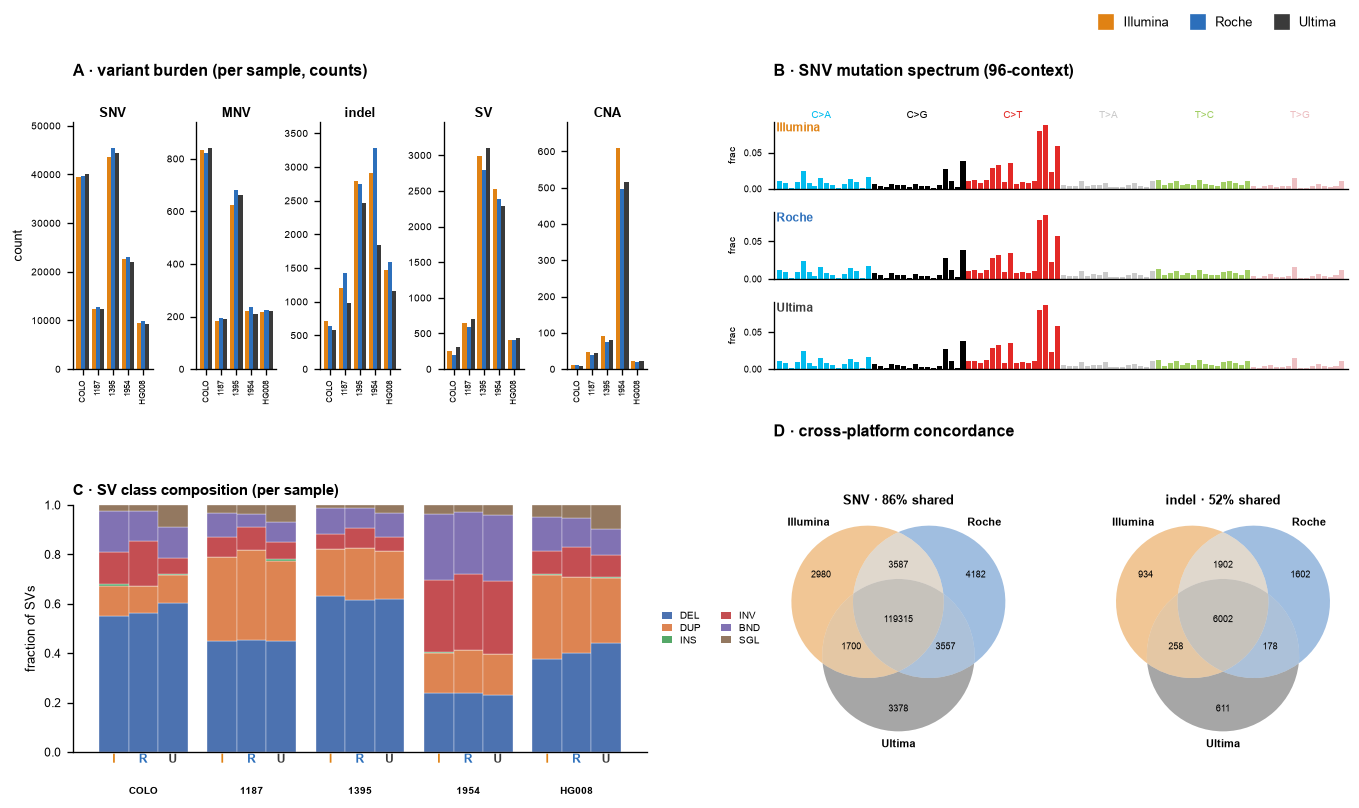

In [8]:
fig = composite_figure(vaf=False)
stem = EXPORT_DIR / "molecular_platform_overview"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()

## 9 · Panels B/C/D — composite, VAF ≥ 10% subset

Wrote: figures/molecular_platform_overview_vaf10.pdf figures/molecular_platform_overview_vaf10.svg figures/molecular_platform_overview_vaf10.png


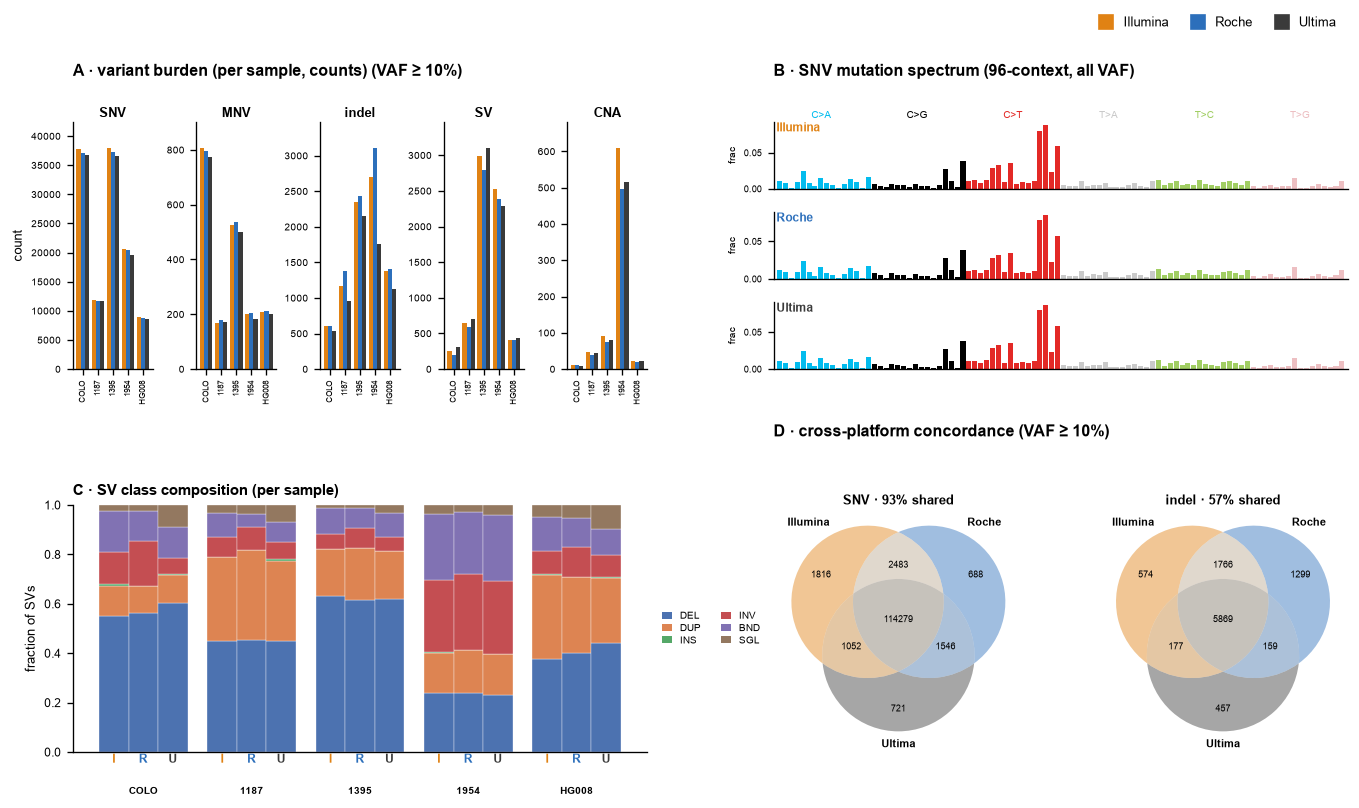

In [9]:
fig = composite_figure(vaf=True)
stem = EXPORT_DIR / "molecular_platform_overview_vaf10"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()